In [ ]:
import pandas as pd
import requests
import re
import matplotlib.pyplot as plt

In [ ]:
plt.rcParams['figure.figsize'] = (14, 7)

def baixar_e_tratar_dados_bcb():
    url = (
        "https://olinda.bcb.gov.br/olinda/servico/taxaJuros/versao/v2/odata/"
        "TaxasJurosMensalPorMes?"
        "$top=5000&$format=json"
        "&$select=Mes,Modalidade,InstituicaoFinanceira,TaxaJurosAoMes,anoMes"
    )

    session = requests.Session()
    session.headers.update({
        'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/122.0.0.0 Safari/537.36',
        'Accept': 'application/json, text/plain, */*',
        'Accept-Language': 'pt-BR,pt;q=0.9,en-US;q=0.8,en;q=0.7',
        'Referer': 'https://olinda.bcb.gov.br/'
    })

    response = session.get(url)

    if response.status_code != 200:
        print(f"Erro ao acessar a API. Status: {response.status_code}")
        return pd.DataFrame()

    dados = response.json().get('value', [])
    if not dados:
        print("Nenhum dado retornado pela API.")
        return pd.DataFrame()

    df = pd.DataFrame(dados)

    def limpar_texto(texto):
        if pd.isna(texto):
            return ""
        texto_str = str(texto)
        texto_limpo = re.sub(r'[^\w\sÀ-ú\-]', '', texto_str)
        return re.sub(r'\s+', ' ', texto_limpo).strip()

    for col in ['Mes', 'Modalidade', 'InstituicaoFinanceira']:
        if col in df.columns:
            df[col] = df[col].apply(limpar_texto)

    if 'TaxaJurosAoMes' in df.columns:
        df['TaxaJurosAoMes'] = pd.to_numeric(df['TaxaJurosAoMes'], errors='coerce')

    return df.dropna(subset=['TaxaJurosAoMes']).copy()

df_processado = baixar_e_tratar_dados_bcb()

instituicoes_desejadas = [
    "BANCO SICOOB S.A.",
    "BANCO COOPERATIVO SICREDI",
    "ITAÚ UNIBANCO S.A.",
    "CAIXA ECONOMICA FEDERAL",
    "BCO SANTANDER (BRASIL) S.A.",
    "BCO BRADESCO S.A.",
    "BANCO INTER",
    "BCO DO BRASIL S.A."
]

Registros filtrados com sucesso: 10


,Mes,Modalidade,InstituicaoFinanceira,TaxaJurosAoMes,anoMes,Instituicao_Upper
0,Set-2026,Financiamento imobiliário com taxas de mercado...,CAIXA ECONOMICA FEDERAL,0.87,2026-09,CAIXA ECONOMICA FEDERAL
2,Set-2026,Financiamento imobiliário com taxas de mercado...,BCO SANTANDER BRASIL SA,1.17,2026-09,BCO SANTANDER BRASIL SA
7,Set-2026,Financiamento imobiliário com taxas de mercado...,BANCO SICOOB SA,0.86,2026-09,BANCO SICOOB SA
10,Set-2026,Financiamento imobiliário com taxas de mercado...,BANCO COOPERATIVO SICREDI,0.92,2026-09,BANCO COOPERATIVO SICREDI
11,Set-2026,Financiamento imobiliário com taxas de mercado...,CAIXA ECONOMICA FEDERAL,0.95,2026-09,CAIXA ECONOMICA FEDERAL
12,Set-2026,Financiamento imobiliário com taxas de mercado...,ITAÚ UNIBANCO SA,0.96,2026-09,ITAÚ UNIBANCO SA
13,Set-2026,Financiamento imobiliário com taxas de mercado...,BCO BRADESCO SA,0.97,2026-09,BCO BRADESCO SA
14,Set-2026,Financiamento imobiliário com taxas de mercado...,BCO SANTANDER BRASIL SA,0.97,2026-09,BCO SANTANDER BRASIL SA
15,Set-2026,Financiamento imobiliário com taxas de mercado...,BANCO INTER,1.02,2026-09,BANCO INTER
16,Set-2026,Financiamento imobiliário com taxas de mercado...,BCO DO BRASIL SA,1.13,2026-09,BCO DO BRASIL SA


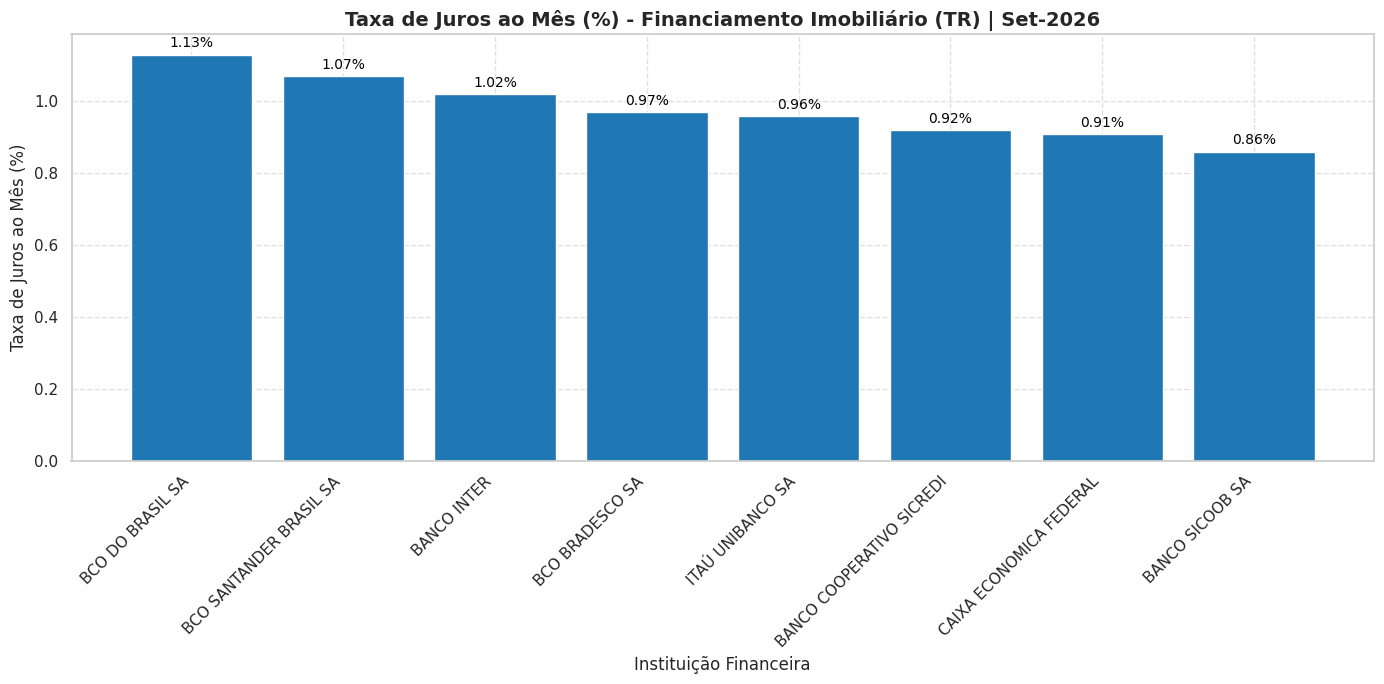

In [ ]:
if not df_processado.empty:
    def limpar_texto(texto):
        if pd.isna(texto):
            return ""
        texto_str = str(texto)
        texto_limpo = re.sub(r'[^\w\sÀ-ú\-]', '', texto_str)
        return re.sub(r'\s+', ' ', texto_limpo).strip()

    df_processado['Instituicao_Upper'] = df_processado['InstituicaoFinanceira'].str.upper()

    bancos_upper = [limpar_texto(b).upper() for b in instituicoes_desejadas]

    df_final_filtrado = df_processado[
        (df_processado['Mes'].str.strip() == "Set-2026") &
        (df_processado['Modalidade'].str.contains("Financiamento imobiliário com taxas de mercado", case=False, na=False)) &
        (df_processado['Instituicao_Upper'].isin(bancos_upper))
    ].copy()

    print(f"Registros filtrados com sucesso: {len(df_final_filtrado)}")
    display(df_final_filtrado.head(10))

    if not df_final_filtrado.empty:
        df_agrupado = (
            df_final_filtrado.groupby('InstituicaoFinanceira', as_index=False)['TaxaJurosAoMes']
            .mean()
            .sort_values(by='TaxaJurosAoMes', ascending=False)
        )

        plt.figure()
        bars = plt.bar(
            df_agrupado['InstituicaoFinanceira'],
            df_agrupado['TaxaJurosAoMes'],
            color='#1f77b4'
        )

        plt.title("Taxa de Juros ao Mês (%) - Financiamento Imobiliário (TR) | Set-2026", fontsize=14, fontweight='bold')
        plt.xlabel("Instituição Financeira", fontsize=12)
        plt.ylabel("Taxa de Juros ao Mês (%)", fontsize=12)
        plt.xticks(rotation=45, ha='right')
        plt.grid(True, linestyle='--', alpha=0.6)

        for bar in bars:
            height = bar.get_height()
            if height > 0:
                plt.annotate(
                    f'{height:.2f}%',
                    (bar.get_x() + bar.get_width() / 2., height),
                    ha='center', va='bottom',
                    fontsize=10, color='black',
                    xytext=(0, 3),
                    textcoords='offset points'
                )

        plt.tight_layout()
        plt.show()
    else:
        print("Nenhum dado encontrado com os filtros aplicados para Set-2026.")
else:
    print("Falha ao carregar o dataset principal.")